# Exploratory Analysis of Housing Data
**R** · Dataset `house_data.csv`

This analysis examines the distribution of `MEDV`, its associations with six numerical variables,
and differences between the `CHAS` groups. Run the cells in order from the directory containing
`house_data.csv`.

## 1. Load and inspect the data

In [1]:
options(width = 100, repr.plot.width = 9, repr.plot.height = 5, repr.plot.res = 144)
df <- read.csv("house_data.csv")
variables <- c("RM", "AGE", "DIS", "TAX", "PTRATIO", "LSTAT", "MEDV")
target <- "MEDV"

cat("Rows:", nrow(df), " columns:", ncol(df), "\n")
print(data.frame(Type = sapply(df, class), Missing = colSums(is.na(df))))
cat("Duplicate rows:", sum(duplicated(df)), "\n")
stopifnot(setequal(na.omit(df$CHAS), c(0, 1)))
df$CHAS <- factor(df$CHAS, levels = c(0, 1))
print(table(df$CHAS, useNA = "ifany"))

numeric_df <- df[variables]
stopifnot(all(sapply(numeric_df, is.numeric)))
for (column in variables) {
  numeric_df[[column]][!is.finite(numeric_df[[column]])] <- NA
}
complete_data <- na.omit(numeric_df)
stopifnot(nrow(complete_data) >= 4,
          all(sapply(complete_data, function(x) length(unique(x)) > 1)))
cat("Complete rows for correlations:", nrow(complete_data), "\n")

Rows: 506  columns: 14 


           Type Missing
CRIM    numeric       0
ZN      numeric       0
INDUS   numeric       0
CHAS    integer       0
NX      numeric       0
RM      numeric       0
AGE     numeric       0
DIS     numeric       0
RAD     integer       0
TAX     numeric       0
PTRATIO numeric       0
B       numeric       0
LSTAT   numeric       0
MEDV    numeric       0


Duplicate rows: 0 



  0   1 
471  35 


Complete rows for correlations: 506 


The dataset has 506 rows and 14 columns, with no missing values or duplicate rows. We treat
`CHAS` as a categorical variable. Descriptive statistics omit invalid values column by column,
and correlations use the same set of complete rows. All 506 observations are available for
every calculation. Potential outliers are retained.

## 2. Descriptive statistics

The sample variance and standard deviation use n − 1 in the variance denominator.
We use linear interpolation in pandas and type 7 quantiles in R. The IQR is Q3 − Q1.

In [2]:
q1 <- sapply(numeric_df, quantile, 0.25, na.rm = TRUE, type = 7)
q3 <- sapply(numeric_df, quantile, 0.75, na.rm = TRUE, type = 7)
iqr <- q3 - q1

summary_table <- data.frame(
  N = colSums(!is.na(numeric_df)),
  Mean = sapply(numeric_df, mean, na.rm = TRUE),
  Median = sapply(numeric_df, median, na.rm = TRUE),
  Variance = sapply(numeric_df, var, na.rm = TRUE),
  SD = sapply(numeric_df, sd, na.rm = TRUE),
  Min = sapply(numeric_df, min, na.rm = TRUE),
  Q1 = q1, Q3 = q3,
  Max = sapply(numeric_df, max, na.rm = TRUE)
)
summary_table$Range <- summary_table$Max - summary_table$Min
summary_table$IQR <- iqr
print(round(summary_table, 3))

          N    Mean  Median  Variance      SD     Min      Q1      Q3     Max   Range     IQR
RM      506   6.285   6.208     0.494   0.703   3.561   5.886   6.624   8.780   5.219   0.738
AGE     506  68.575  77.500   792.358  28.149   2.900  45.025  94.075 100.000  97.100  49.050
DIS     506   3.795   3.207     4.434   2.106   1.130   2.100   5.188  12.126  10.997   3.088
TAX     506 408.237 330.000 28404.759 168.537 187.000 279.000 666.000 711.000 524.000 387.000
PTRATIO 506  18.456  19.050     4.687   2.165  12.600  17.400  20.200  22.000   9.400   2.800
LSTAT   506  12.653  11.360    50.995   7.141   1.730   6.950  16.955  37.970  36.240  10.005
MEDV    506  22.533  21.200    84.587   9.197   5.000  17.025  25.000  50.000  45.000   7.975


The median `MEDV` is 21.2, and the middle 50% of values lie between 17.025 and 25.0.
The mean of 22.533 is above the median, and the standard deviation is 9.197 in `MEDV` units.

## 3. Distributions and potential outliers

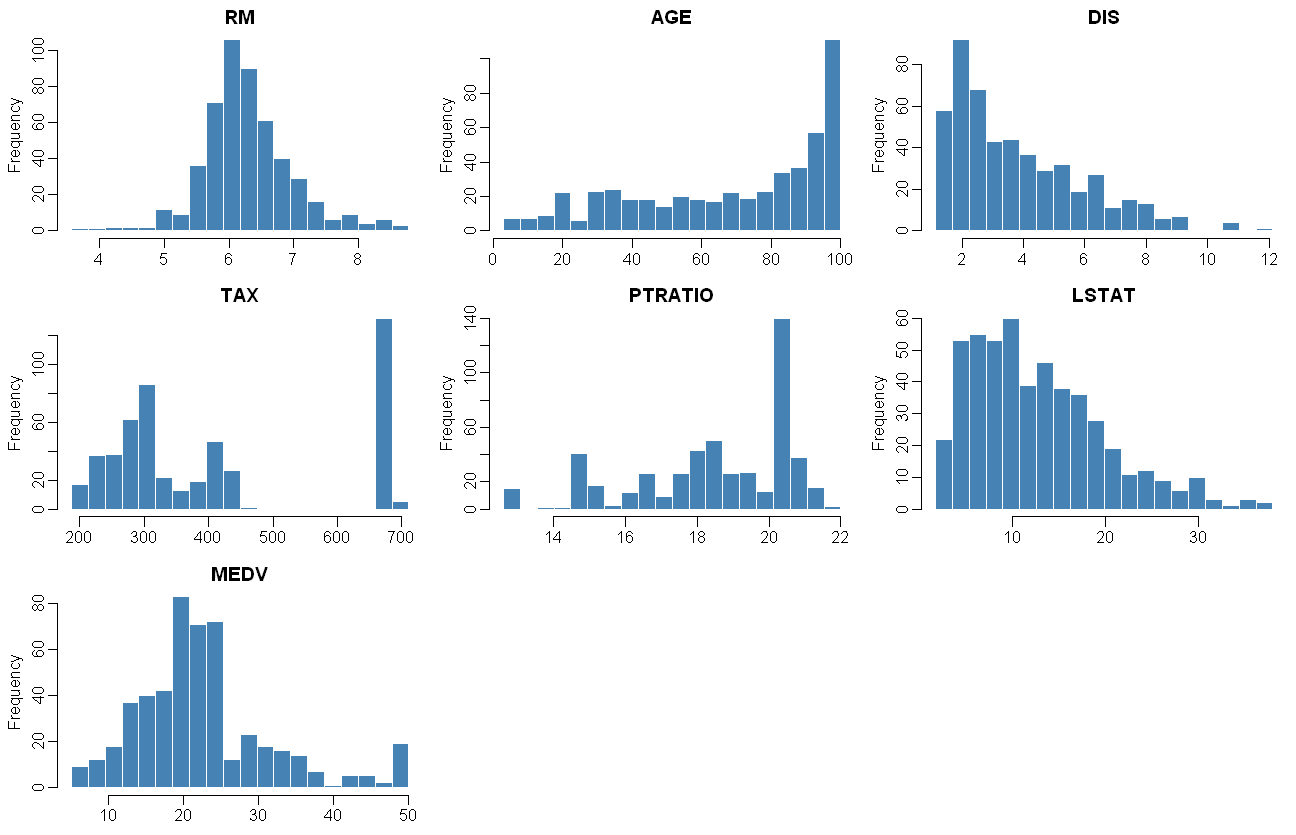

In [3]:
options(repr.plot.height = 5.8)
old_par <- par(mfrow = c(3, 3), mar = c(2.1, 3.05, 1.7, 0.5),
               mgp = c(1.8, 0.55, 0))
for (column in variables) {
  x <- na.omit(numeric_df[[column]])
  breaks <- seq(min(x), max(x), length.out = 21)
  hist(x, breaks = breaks, right = FALSE, main = column,
       xlab = "", ylab = "Frequency", col = "steelblue", border = "white")
}
par(old_par)

- Most `MEDV` values are around 15 to 25, with a long right tail and a cluster at the observed maximum of 50.
- `RM` peaks around 6 and is roughly symmetric near the center, with a few extreme values in both tails.
- `DIS` and `LSTAT` are right-skewed. `AGE` values cluster near the upper end of their range.
- `TAX` has several distinct clusters, with a particularly frequent value of 666.

## 3. Distributions · Boxplots

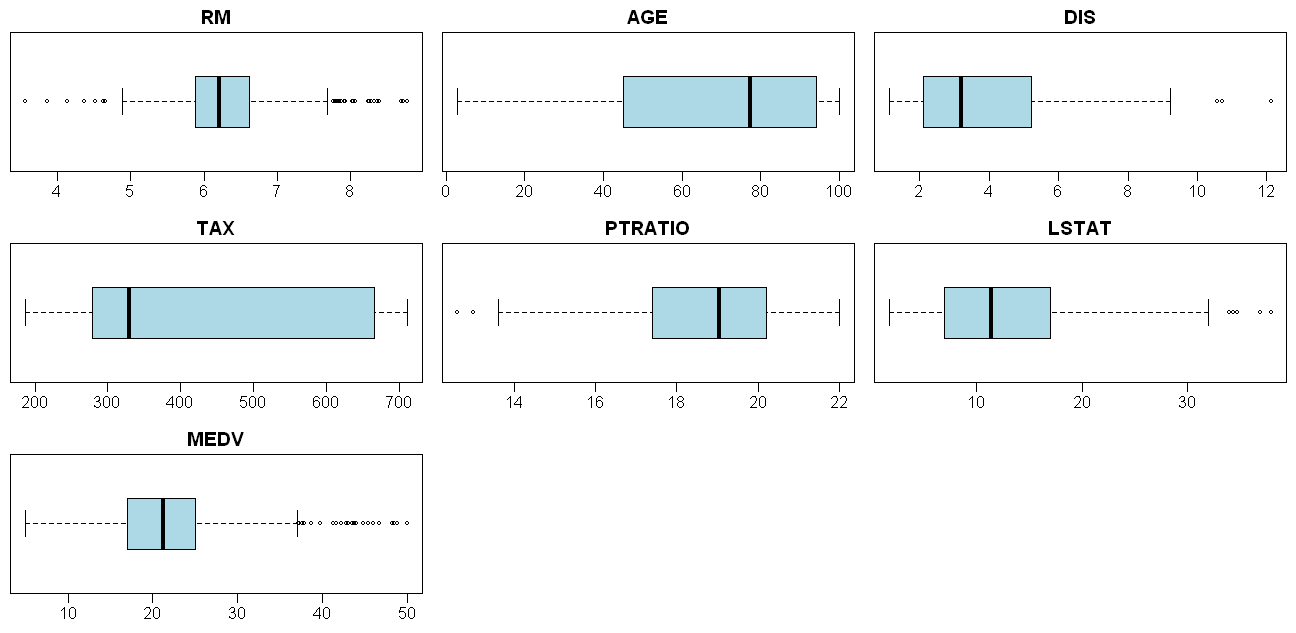

In [4]:
options(repr.plot.height = 4.4)
old_par <- par(mfrow = c(3, 3), mar = c(2.1, 0.55, 1.7, 0.5),
               mgp = c(1.8, 0.55, 0))
for (column in variables) {
  boxplot(numeric_df[[column]], horizontal = TRUE, range = 1.5,
          main = column, col = "lightblue", outline = TRUE, axes = FALSE,
          outcex = 0.55)
  axis(1)
  box()
}
par(old_par)

Each boxplot shows the median and the middle 50% of values on the variable's own scale.
Base R boxplots use Tukey hinges. The following table applies the quartiles from Step 2 in both
languages so the outlier counts are directly comparable.

## 3. Distributions · The 1.5 × IQR rule

In [5]:
lower_limits <- q1 - 1.5 * iqr
upper_limits <- q3 + 1.5 * iqr
below <- sweep(as.matrix(numeric_df), 2, lower_limits, "<")
above <- sweep(as.matrix(numeric_df), 2, upper_limits, ">")
flagged_rows <- rowSums(below | above, na.rm = TRUE) > 0

outlier_summary <- data.frame(
  Lower_limit = lower_limits, Upper_limit = upper_limits,
  Below = colSums(below, na.rm = TRUE),
  Above = colSums(above, na.rm = TRUE)
)
outlier_summary$Flagged <- outlier_summary$Below + outlier_summary$Above
print(round(outlier_summary, 3))
cat("Rows flagged in at least one variable:", sum(flagged_rows), "\n")
cat("MEDV values at the observed maximum:",
    sum(numeric_df[[target]] == 50, na.rm = TRUE), "\n")

examples <- numeric_df[c(which.min(numeric_df$RM), which.max(numeric_df$RM),
                        which.max(numeric_df$DIS), which.min(numeric_df[[target]]),
                        which.max(numeric_df[[target]])), ]
rownames(examples) <- c("Min RM", "Max RM", "Max DIS", "Min MEDV", "Max MEDV")
print(round(examples, 3))

            Lower_limit Upper_limit Below Above Flagged
RM.25%            4.779       7.730     8    22      30
AGE.25%         -28.550     167.650     0     0       0
DIS.25%          -2.532       9.821     0     5       5
TAX.25%        -301.500    1246.500     0     0       0
PTRATIO.25%      13.200      24.400    15     0      15
LSTAT.25%        -8.058      31.963     0     7       7
MEDV.25%          5.062      36.963     2    38      40


Rows flagged in at least one variable: 68 


MEDV values at the observed maximum: 16 


            RM   AGE    DIS TAX PTRATIO LSTAT MEDV
Min RM   3.561  87.9  1.613 666    20.2  7.12 27.5
Max RM   8.780  82.9  1.905 666    20.2  5.29 21.9
Max DIS  6.728  36.1 12.126 187    17.0  4.50 30.1
Min MEDV 5.453 100.0  1.490 666    20.2 30.59  5.0
Max MEDV 7.489  90.8  1.971 403    14.7  1.73 50.0


For `MEDV`, 38 values are above the upper limit and 2 are below the lower limit.
The maximum of 50 appears 16 times, suggesting a possible measurement ceiling.
The smallest and largest `RM` values (3.561 and 8.780) have `MEDV` values of 27.5 and 21.9,
respectively. These observations sit far out on the horizontal axis in the scatterplot.
All records remain in the analysis.

## 4. Compare the CHAS groups

  Count   Mean Median     SD   IQR
0   471 22.094   20.9  8.831  8.20
1    35 28.440   23.3 11.817 12.05


Mean difference (1 - 0): 6.346 


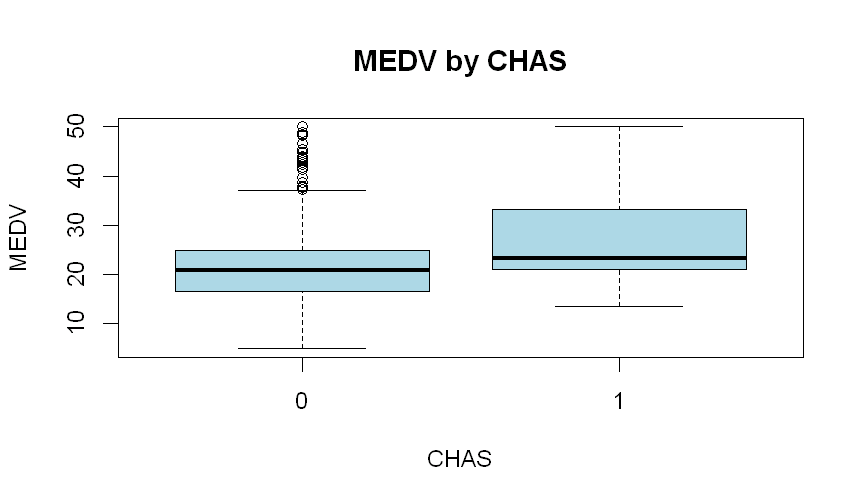

In [6]:
groups <- split(numeric_df[[target]], df$CHAS)
group_summary <- data.frame(
  Count = sapply(groups, function(x) sum(!is.na(x))),
  Mean = sapply(groups, mean, na.rm = TRUE),
  Median = sapply(groups, median, na.rm = TRUE),
  SD = sapply(groups, sd, na.rm = TRUE),
  IQR = sapply(groups, IQR, na.rm = TRUE, type = 7)
)
print(round(group_summary, 3))
mean_difference <- group_summary["1", "Mean"] - group_summary["0", "Mean"]
cat("Mean difference (1 - 0):", round(mean_difference, 3), "\n")

options(repr.plot.width = 6, repr.plot.height = 3.5)
boxplot(groups, xlab = "CHAS", ylab = target, main = "MEDV by CHAS",
        col = "lightblue")

In the `CHAS = 1` group, the mean `MEDV` is 6.346 higher and the median is 2.4 higher.
The group also has a larger standard deviation and IQR. The distributions overlap,
and the groups differ considerably in size (471 observations for `CHAS = 0` and 35 for
`CHAS = 1`). The comparison is descriptive and does not adjust for other variables.

## 5. Scatterplots and local smoothing

Each scatterplot uses a local linear smoother with a span of 0.70.
The `LSTAT` plot also includes a curve with a span of 0.30.

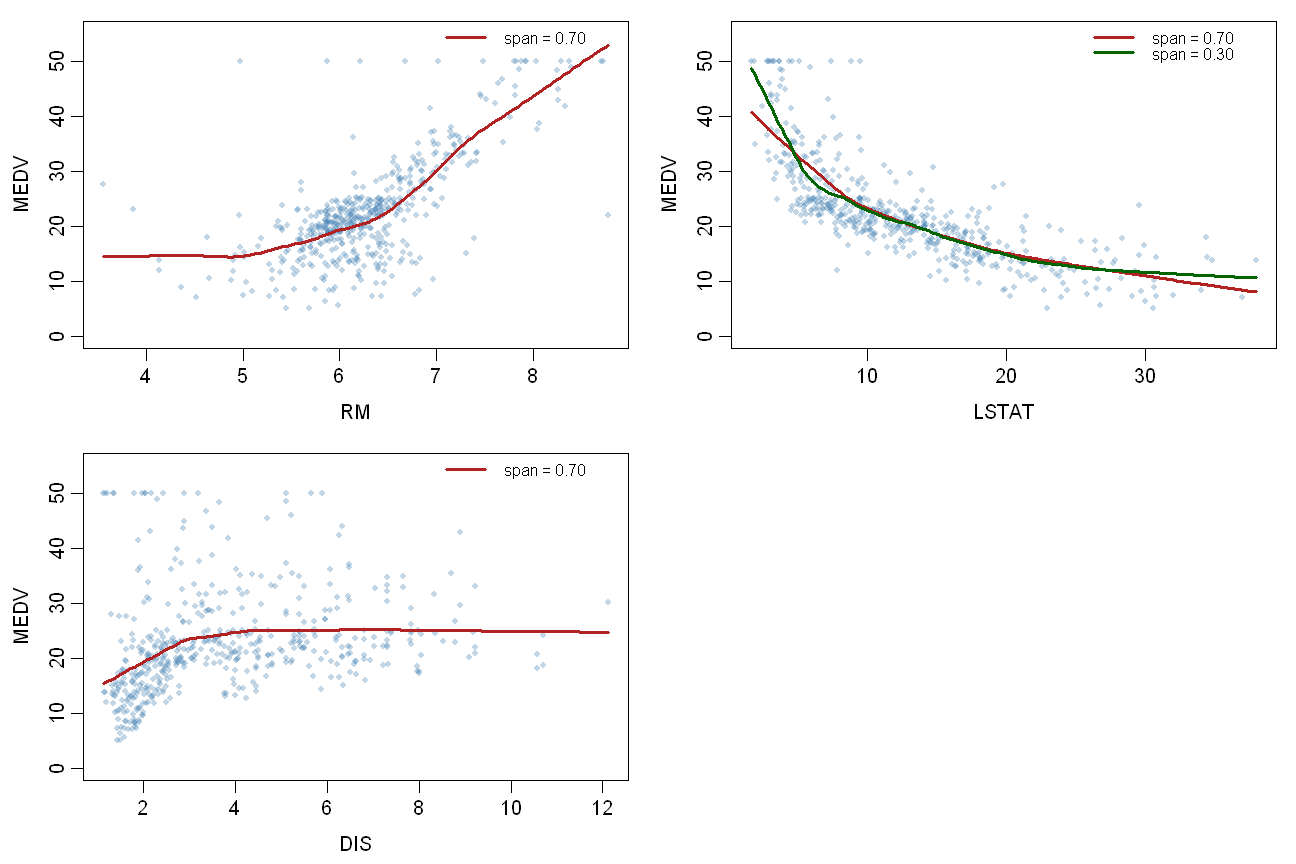

In [7]:
predictors <- c("RM", "LSTAT", "DIS")
options(repr.plot.width = 9, repr.plot.height = 6)
old_par <- par(mfrow = c(2, 2), mar = c(3.5, 3.5, 0.9, 0.8),
               mgp = c(2.15, 0.65, 0))
for (predictor in predictors) {
  pair_data <- na.omit(data.frame(x = numeric_df[[predictor]],
                                  y = numeric_df[[target]]))
  x_grid <- seq(min(pair_data$x), max(pair_data$x), length.out = 150)
  plot(y ~ x, data = pair_data, xlab = predictor, ylab = target, ylim = c(0, 55),
       pch = 16, cex = 0.65, col = adjustcolor("steelblue", alpha.f = 0.32))
  spans <- if (predictor == "LSTAT") c(0.70, 0.30) else 0.70
  colors <- c("firebrick", "darkgreen")[seq_along(spans)]
  for (i in seq_along(spans)) {
    fit <- loess(y ~ x, data = pair_data, span = spans[i], degree = 1,
                 family = "gaussian", control = loess.control(surface = "direct"))
    lines(x_grid, predict(fit, data.frame(x = x_grid)), col = colors[i], lwd = 2)
  }
  legend("topright", sprintf("span = %.2f", spans), col = colors,
         lty = 1, lwd = 2, bty = "n", cex = 0.8)
}
par(old_par)

## 5. Scatterplots · Interpretation

- **RM.** `MEDV` generally rises with `RM`. Its spread is greater in the top quarter of `RM`
  than in the middle two quarters. Extreme points such as `RM = 8.780` with `MEDV = 21.9`
  may affect the smooth near the ends, where observations are sparse.
- **LSTAT.** `MEDV` drops sharply as `LSTAT` increases and then declines more gradually.
  At low `LSTAT`, the vertical spread is wider and some values reach 50. The 0.30 span
  captures a sharper initial drop than the 0.70 span.
- **DIS.** `MEDV` rises at first and then levels off. At short distances, low values and values
  of 50 occur together. The vertical spread narrows as `DIS` increases, and observations
  are sparse at the far right.

## 6. Correlation matrices

All three methods use the same 506 rows, variable order, and color scale from −1 to 1.
The heatmaps show coefficients rounded to two decimal places.

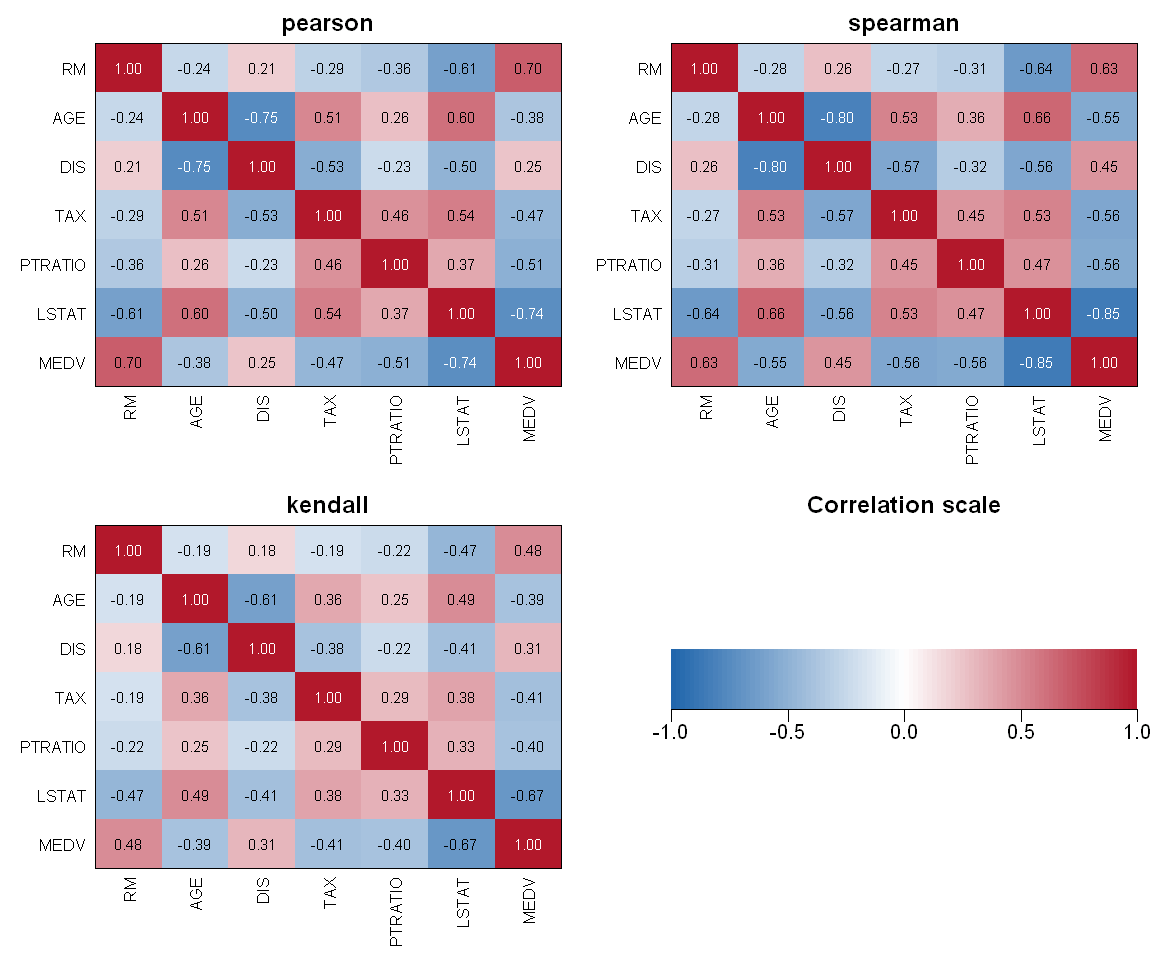

In [8]:
methods <- c("pearson", "spearman", "kendall")
correlation_matrices <- setNames(lapply(methods, function(method) {
  cor(complete_data, method = method)
}), methods)
palette <- colorRampPalette(c("#2166AC", "white", "#B2182B"))(100)
cells <- seq_along(variables)
options(repr.plot.width = 8, repr.plot.height = 6.7)
old_par <- par(mfrow = c(2, 2), mar = c(4, 4, 1.8, 0.6),
               mgp = c(2.1, 0.4, 0))
for (method in methods) {
  mat <- correlation_matrices[[method]]
  image(cells, cells, t(mat[nrow(mat):1, ]), col = palette, zlim = c(-1, 1),
        axes = FALSE, xlab = "", ylab = "", main = method)
  axis(1, at = cells, labels = variables, las = 2, tick = FALSE, cex.axis = 0.8)
  axis(2, at = cells, labels = rev(variables), las = 1, tick = FALSE, cex.axis = 0.8)
  for (i in cells) {
    values <- mat[i, ]
    text(cells, length(cells) + 1 - i, sprintf("%.2f", values), cex = 0.75,
         col = ifelse(abs(values) >= 0.70, "white", "black"))
  }
  box()
}
breaks <- seq(-1, 1, length.out = length(palette) + 1)
plot.new()
plot.window(xlim = c(-1, 1), ylim = c(0, 1), xaxs = "i")
rect(head(breaks, -1), 0.46, tail(breaks, -1), 0.65, col = palette, border = NA)
axis(1, at = seq(-1, 1, 0.5), pos = 0.46)
title(main = "Correlation scale")
par(old_par)

## 6. Correlations · Associations with MEDV

In [9]:
target_correlations <- sapply(correlation_matrices, function(mat) {
  mat[setdiff(variables, target), target]
})
print(round(target_correlations, 3))

        pearson spearman kendall
RM        0.695    0.634   0.483
AGE      -0.377   -0.548  -0.388
DIS       0.250    0.446   0.313
TAX      -0.469   -0.562  -0.415
PTRATIO  -0.508   -0.556  -0.399
LSTAT    -0.738   -0.853  -0.669


- `LSTAT` has the strongest association with `MEDV` across all three matrices.
  Spearman's ρ (−0.853) captures the predominantly monotonic, curved decline in the scatterplot.
  Pearson's r (−0.738) summarizes the linear association.
- Spearman's ρ (0.446) is also suitable for `DIS`. The scatterplot rises and then levels off,
  and Pearson's r (0.250) indicates a weaker linear association. The scatterplot shows how
  the spread and trend change across the range of `DIS`.
- `RM` has a strong positive Pearson correlation (0.695). The absolute value of Kendall's τ
  is smaller than Spearman's ρ for all six pairs. Kendall's τ is based on concordant and
  discordant pairs, so the two coefficients have different interpretations.

## 7. Pearson tests and uncertainty

For each predictor, we run a two-sided test of whether its population Pearson correlation
with `MEDV` is zero. The individual approximate 95% confidence intervals use Fisher's
transformation. The Benjamini-Hochberg (BH) correction treats the six tests as one family.

In [10]:
results <- data.frame()
for (predictor in setdiff(variables, target)) {
  test <- cor.test(complete_data[[predictor]], complete_data[[target]],
                   method = "pearson", alternative = "two.sided", conf.level = 0.95)
  row <- data.frame(
    Variable = predictor, N = nrow(complete_data), r = unname(test$estimate),
    CI_low = test$conf.int[1], CI_high = test$conf.int[2], p_value = test$p.value
  )
  results <- rbind(results, row)
}
results$p_BH <- p.adjust(results$p_value, method = "BH")
results$Reject_BH <- results$p_BH <= 0.05
print(results, digits = 4, row.names = FALSE)

 Variable   N       r  CI_low CI_high   p_value      p_BH Reject_BH
       RM 506  0.6954  0.6474  0.7378 2.487e-74 7.462e-74      TRUE
      AGE 506 -0.3770 -0.4494 -0.2996 1.570e-18 1.884e-18      TRUE
      DIS 506  0.2499  0.1664  0.3299 1.207e-08 1.207e-08      TRUE
      TAX 506 -0.4685 -0.5339 -0.3976 5.638e-29 8.457e-29      TRUE
  PTRATIO 506 -0.5078 -0.5697 -0.4401 1.610e-34 3.219e-34      TRUE
    LSTAT 506 -0.7377 -0.7750 -0.6952 5.081e-88 3.049e-87      TRUE


After BH correction, all six null hypotheses are rejected at the 0.05 level.
`LSTAT` has the largest absolute Pearson correlation (r = −0.738). `DIS` has the weakest
Pearson correlation (r = 0.250) and an adjusted p-value of about 1.21 × 10⁻⁸. The p-value
measures evidence against the null hypothesis. The coefficient and its confidence interval
describe the size and uncertainty of the association.

## 8. Python and R comparison and conclusions

**Python and R.** Comparing outputs at full precision confirmed agreement on the data checks,
descriptive statistics, outlier counts, group summaries, all three correlation matrices,
and all six Pearson tests. The displayed values use different rounding formats.

**Data handling and smoothing.** No values needed imputation, and all rows were complete.
Linear interpolation in pandas and type 7 quantiles in R give the same quartiles and IQR
limits. Base R boxplots use Tukey hinges. Python's LOWESS and R's LOESS both use local linear
regression without robust reweighting. R evaluates the local fit directly
(`surface = "direct"`). On the same 150-point grid, the fitted curves differ by at most
8 × 10⁻¹³ `MEDV` units, which is consistent with floating-point rounding. Other LOESS
settings, such as interpolation, can produce different curves.

**Main findings.** `MEDV` has a right tail, and 16 observations are at its maximum of 50.
The strongest associations are negative with `LSTAT` and positive with `RM`.
The `CHAS = 1` group has a mean `MEDV` that is 6.346 higher, greater variability,
and fewer observations in this sample.

**Limitations.** A possible ceiling in `MEDV`, changing spread in the scatterplots,
and sensitivity to individual observations limit interpretation. Classical Pearson inference
assumes independent observations and approximate bivariate normality. If observations close
to one another are similar, the true uncertainty may be larger. The correlations and group
differences describe unadjusted associations in this dataset.